# RSNA Knee Abnormality Detection — Hasil EDA (dari eksekusi Kaggle)

Notebook ini adalah **hasil yang ditarik kembali dari Kaggle** setelah `rsna_knee_eda.ipynb` (di folder `kaggle_kernel/`) dijalankan penuh terhadap dataset kompetisi asli di server Kaggle (kernel: [`rsna-knee-abnormality-detection-eda`](https://www.kaggle.com/code/dimaspashaakrilian/rsna-knee-abnormality-detection-eda), versi 6).

Gambar-gambar di bawah adalah output asli (PNG) dari eksekusi tersebut, ditanam langsung supaya bisa dilihat sepenuhnya offline.

## Ringkasan angka kunci (dataset penuh)

| Metrik | Nilai |
|---|---|
| Jumlah studi train | **4,407** |
| Jumlah series train | 24,371 (rata-rata **5.53** series/studi) |
| Studi test (sampel publik) | 3 *(code competition — test asli disembunyikan)* |
| Rata-rata label kosong per kolom | **98.68%** |
| Studi dengan ≥1 label terisi | **58 / 4407 (1.32%)** |
| Studi dengan Report terisi | 4407 / 4407 (**100%**) |
| Bahasa laporan (sampel n=1500) | en 584 · es 234 · tr 188 · hr 137 · el 123 · de 79 · bg 71 · nl 56 · fr 28 |
| Rata-rata slice/series (sampel n=300) | 33.7 (min 12, max 320) |
| Gagal baca DICOM (header+pixel, n=400) | **0%** |
| Kombinasi resolusi unik (n=600) | **50** — gambar tidak seragam |
| Vendor scanner (n=600) | **≥10** (Siemens, GE, Philips, Toshiba, Canon, Hitachi, Fujifilm, dst) |
| Kekuatan medan magnet | 1.16T · 1.5T · 3.0T |


## Ketersediaan label

Hanya sebagian sangat kecil kolom label yang terisi — konsisten ~98–99% NaN di seluruh 12 kolom pathology.

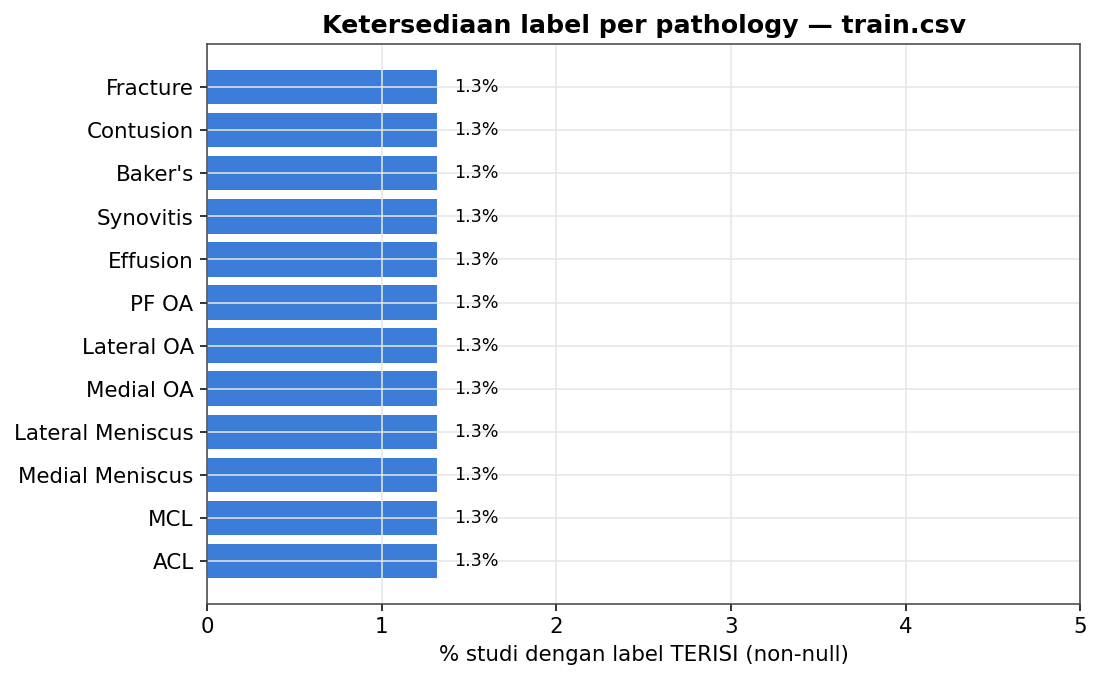

*Persentase studi dengan label terisi per pathology — semuanya di bawah ~2%.*

## Distribusi kelas (pada 58 studi yang berlabel)

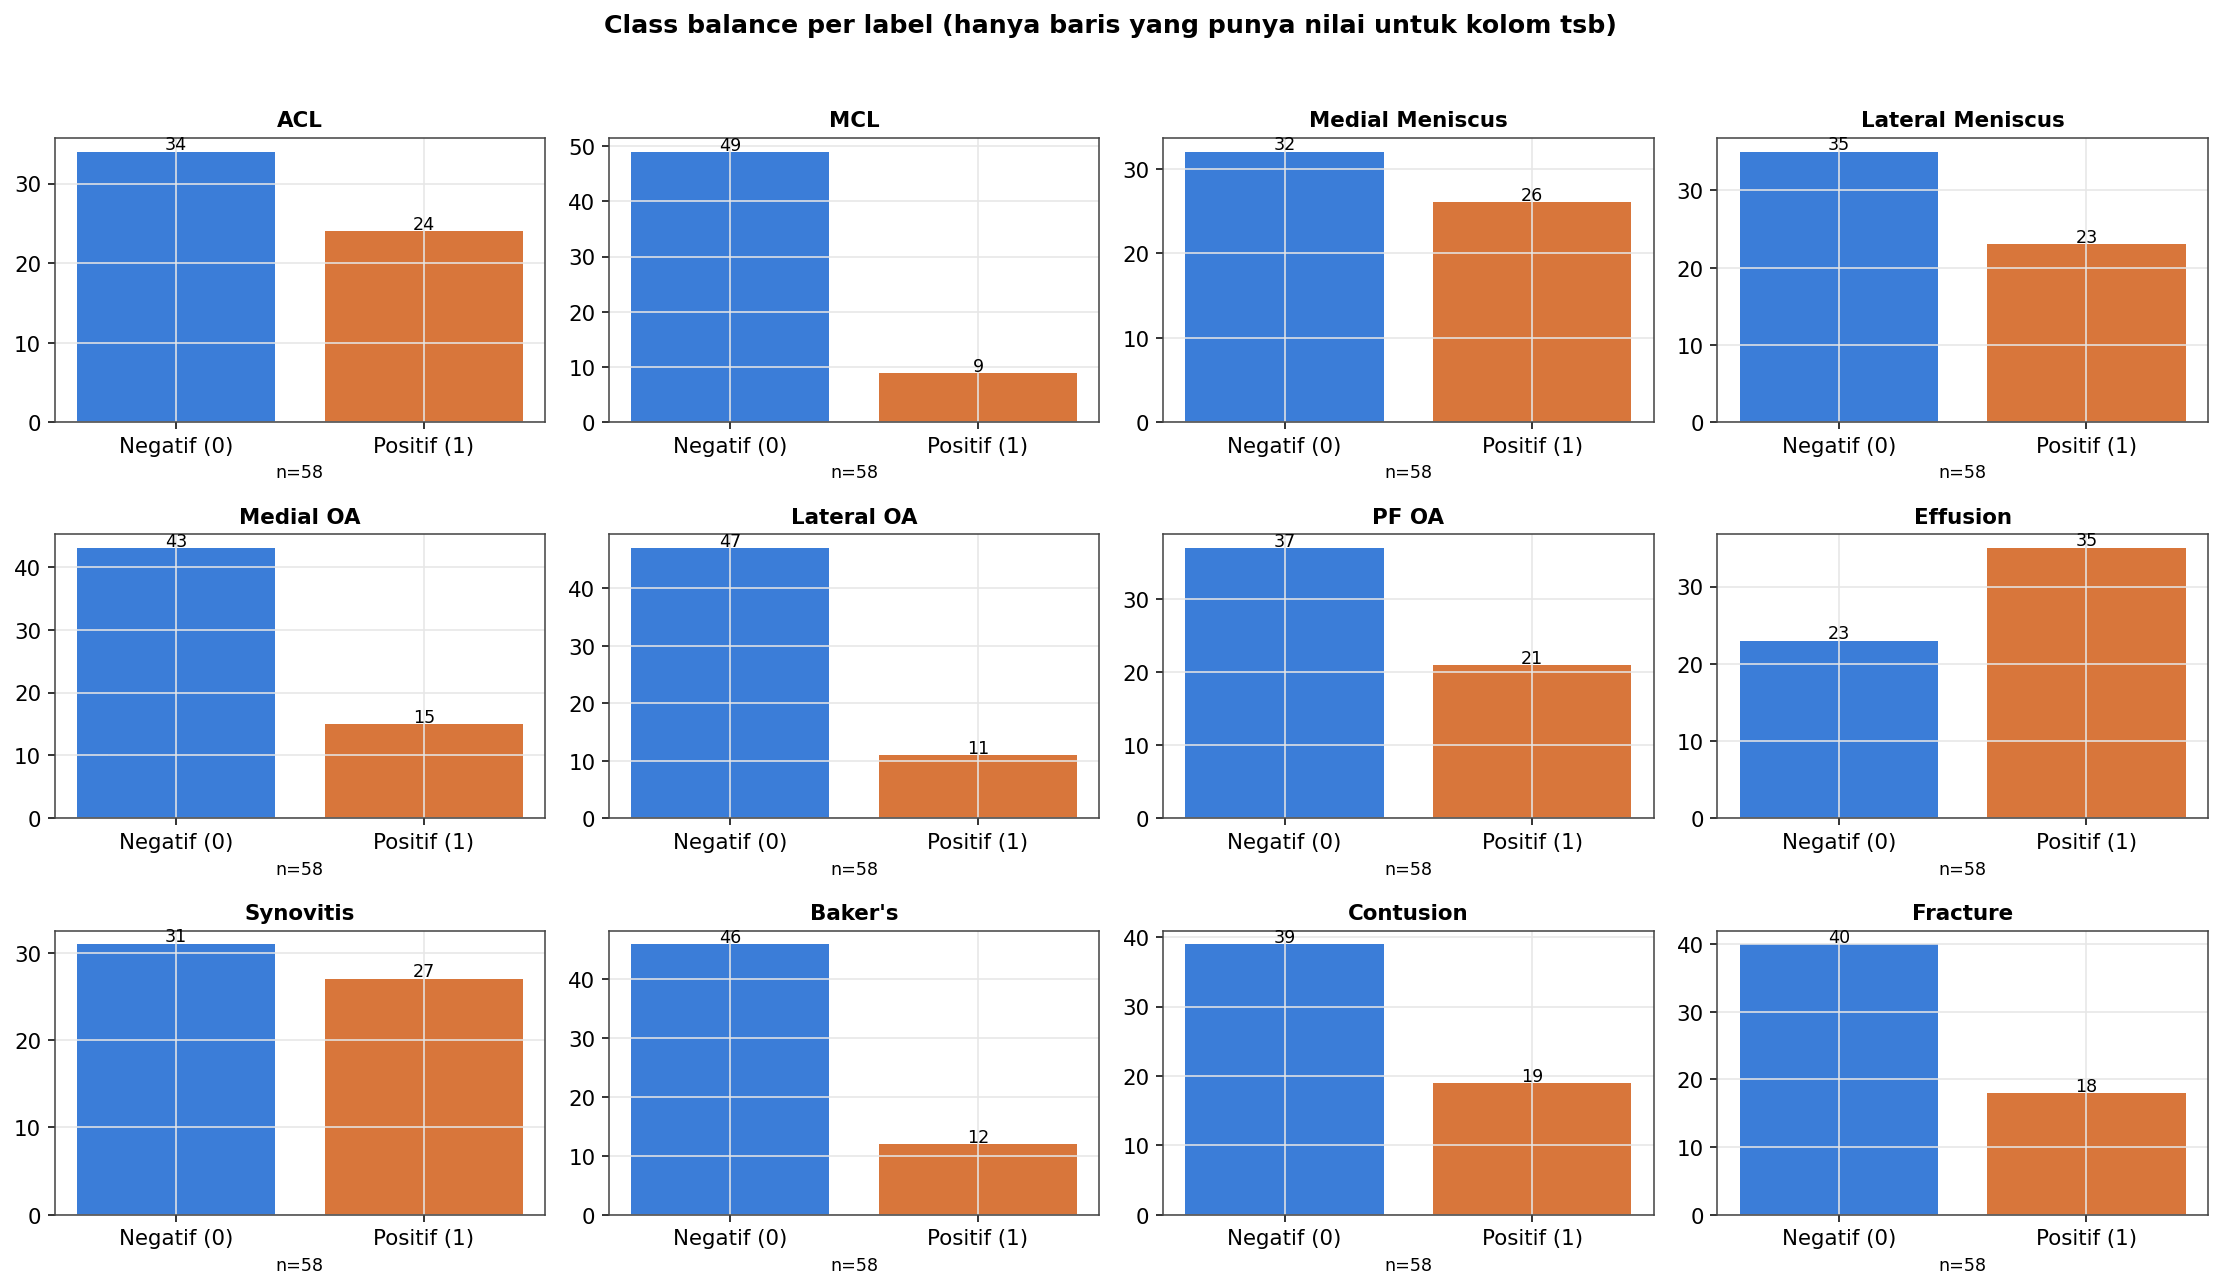

*Class balance per label, dihitung hanya dari baris yang punya nilai non-null untuk kolom tsb.*

## Ko-okurensi antar label

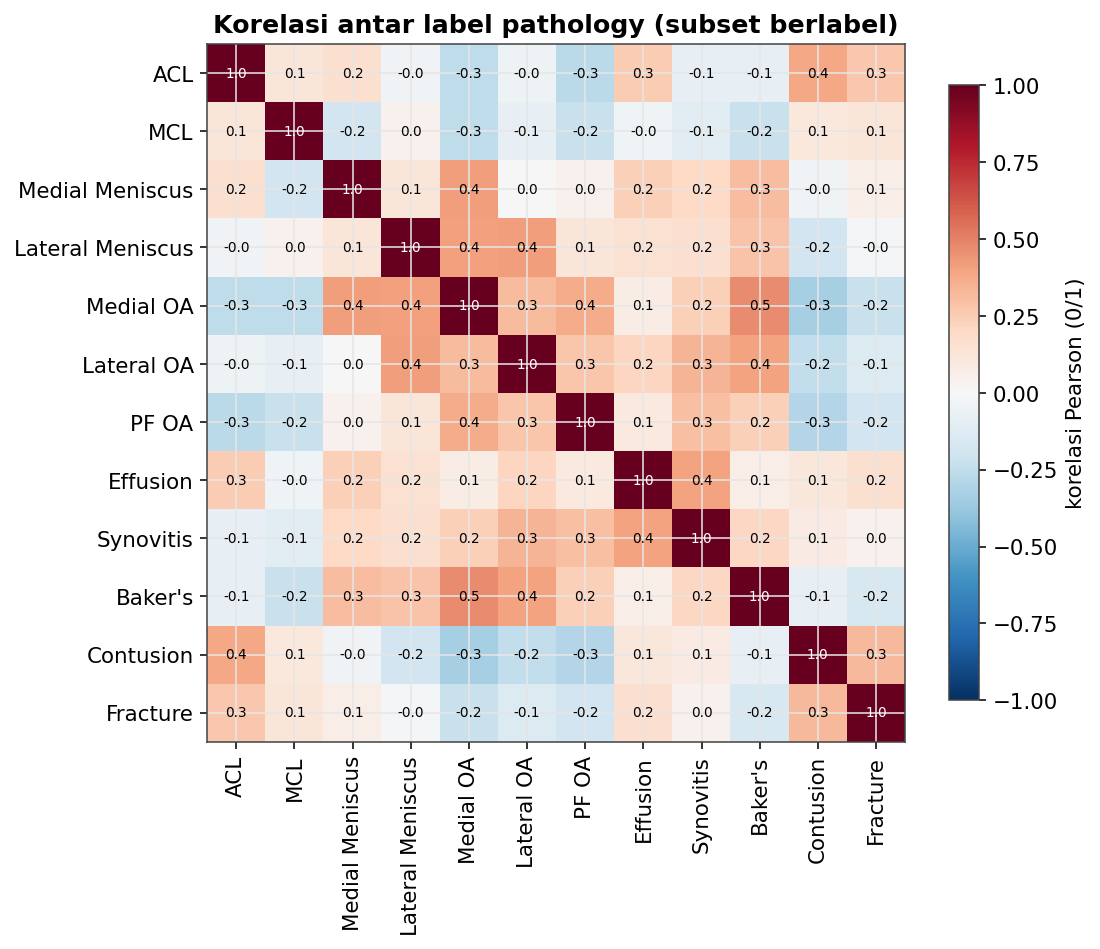

*Korelasi Pearson antar 12 label pathology pada subset berlabel.*

## Jumlah label positif per studi

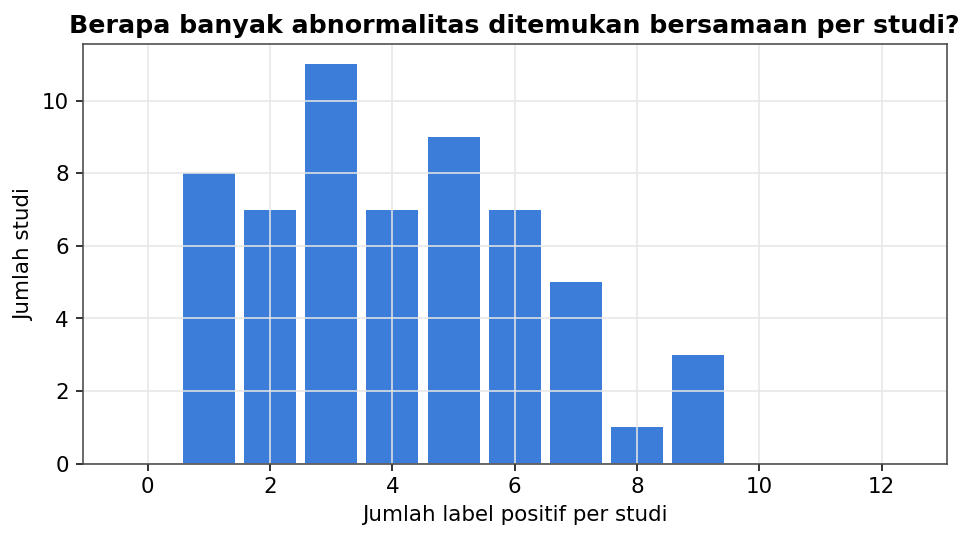

*Distribusi berapa banyak abnormalitas ditemukan bersamaan dalam satu studi.*

## Panjang laporan radiologi

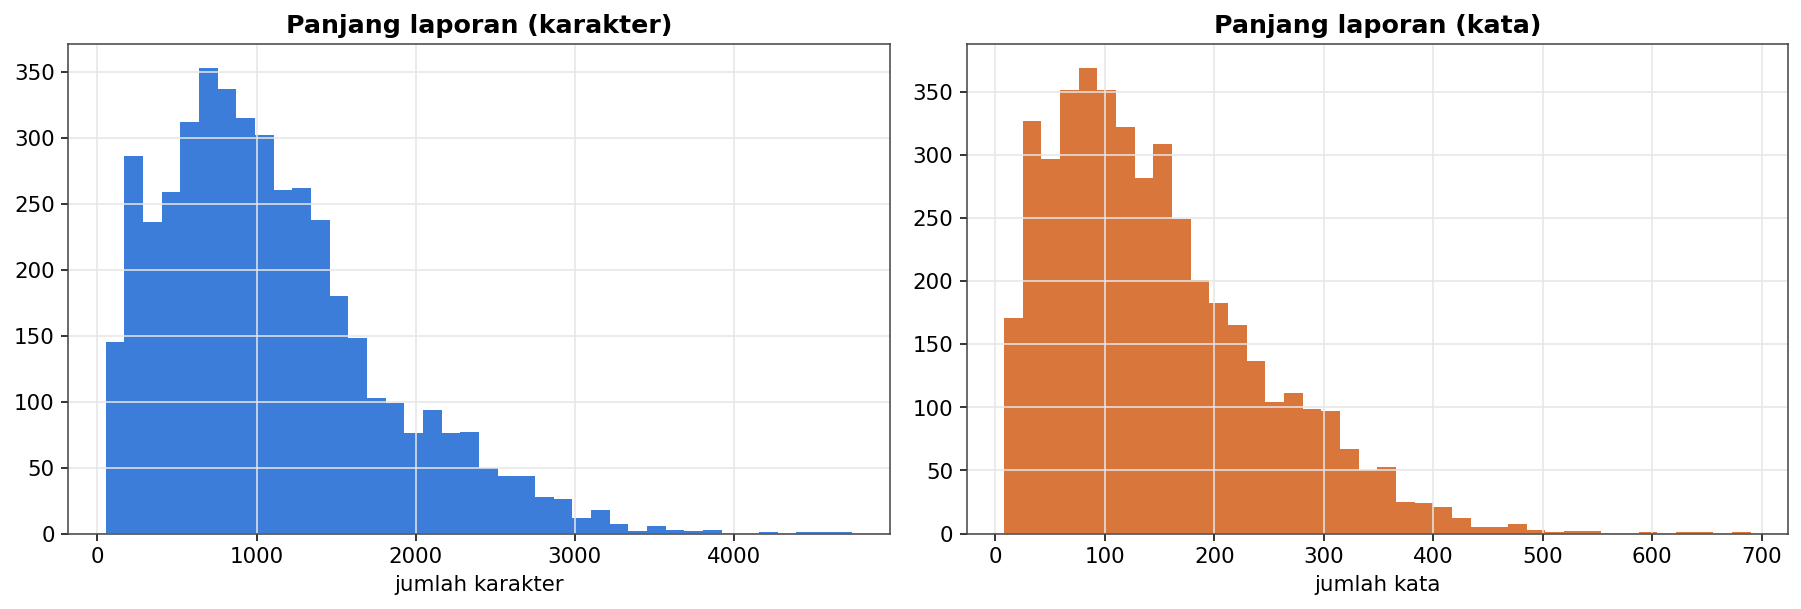

*Distribusi panjang teks Report dalam karakter dan kata.*

## Distribusi bahasa laporan

Dataset ini benar-benar multi-bahasa — laporan berasal dari banyak institusi/negara berbeda.

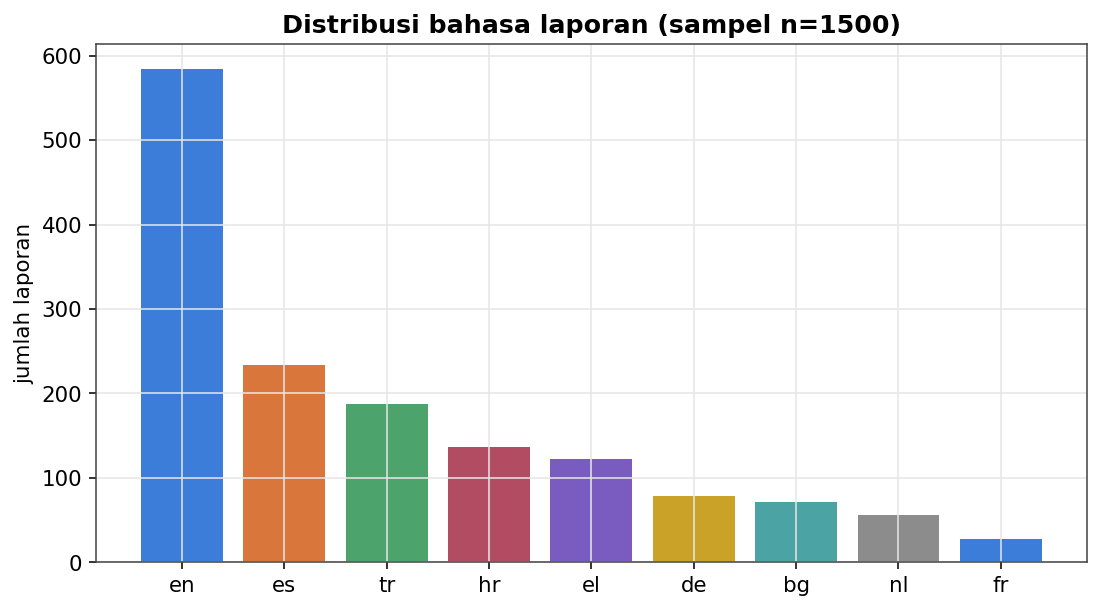

*Deteksi bahasa (langdetect) pada sampel 1500 laporan: English, Spanish, Turkish, Croatian, Greek, German, Bulgarian, Dutch, French mendominasi.*

## Jumlah MRI series per studi

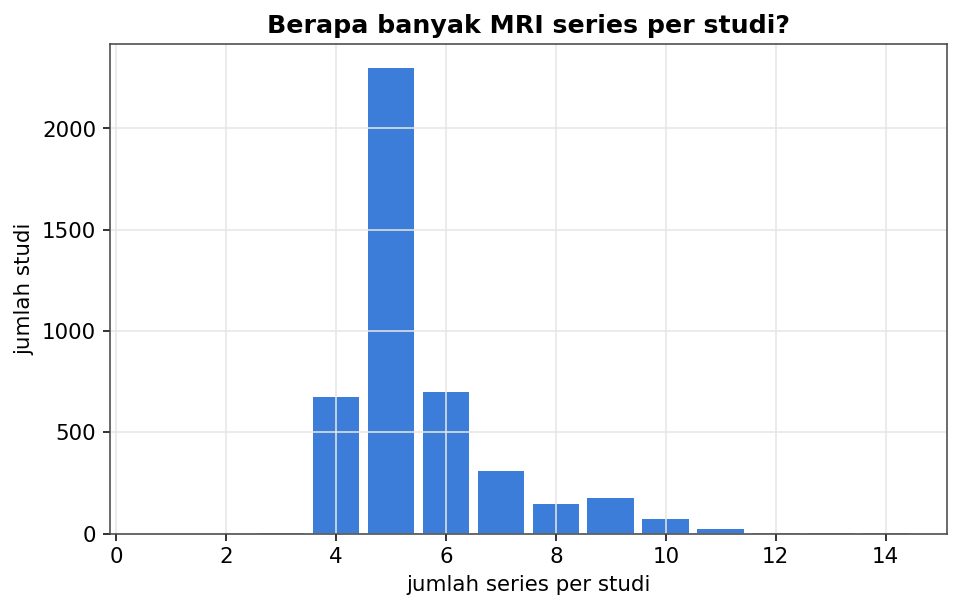

*Sebagian besar studi punya 5-6 series (kombinasi Axial/Sagittal/Coronal + variasi sekuens).*

## Karakteristik sekuens MRI

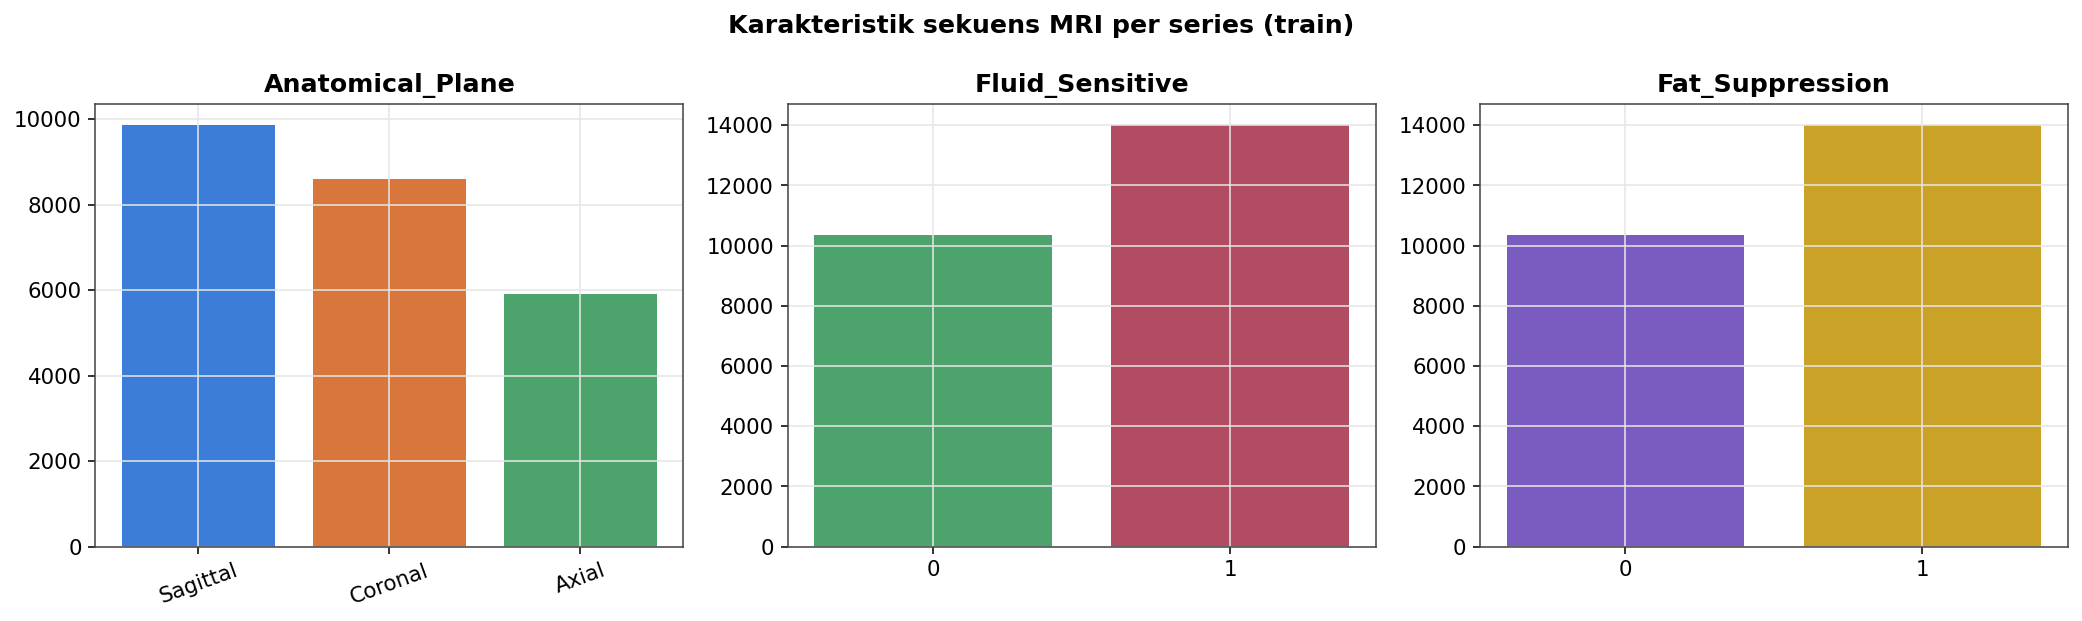

*Distribusi Anatomical_Plane, Fluid_Sensitive, dan Fat_Suppression di seluruh series train.*

## Train vs Test — distribusi Anatomical_Plane

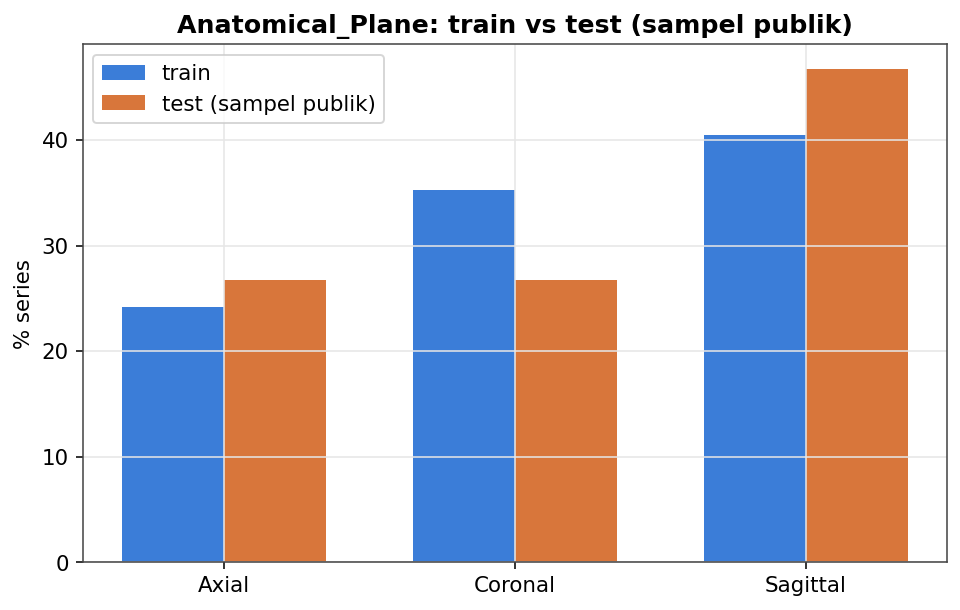

*Perbandingan proporsi bidang anatomis antara train dan sampel test publik.*

## Contoh slice MRI

Slice tengah dari 8 series acak, ditampilkan bersama metadata (plane, fluid-sensitive, fat-suppression).

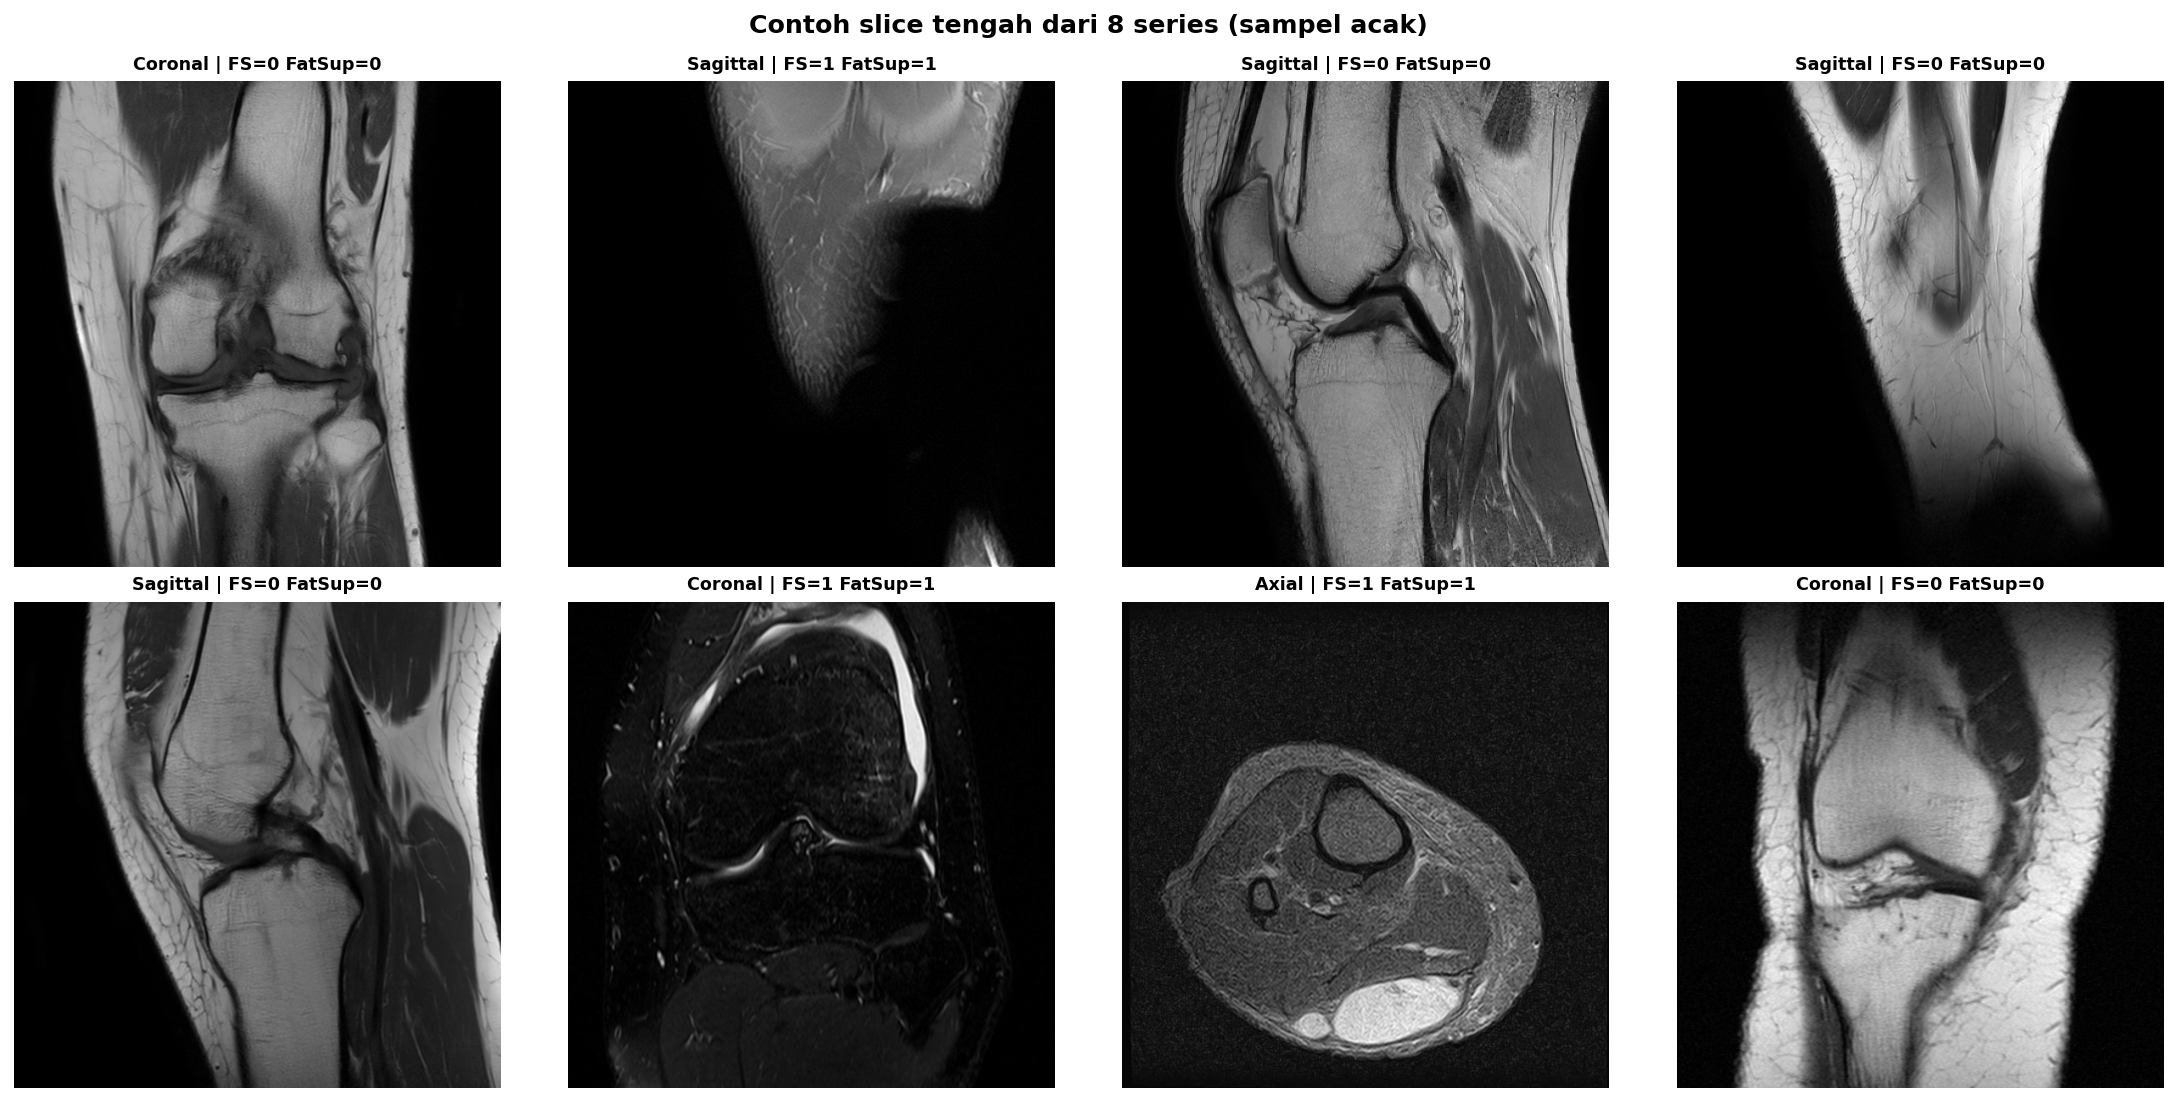

*Contoh visual variasi tampilan antar plane dan sekuens.*

## Jumlah slice (instance) per series

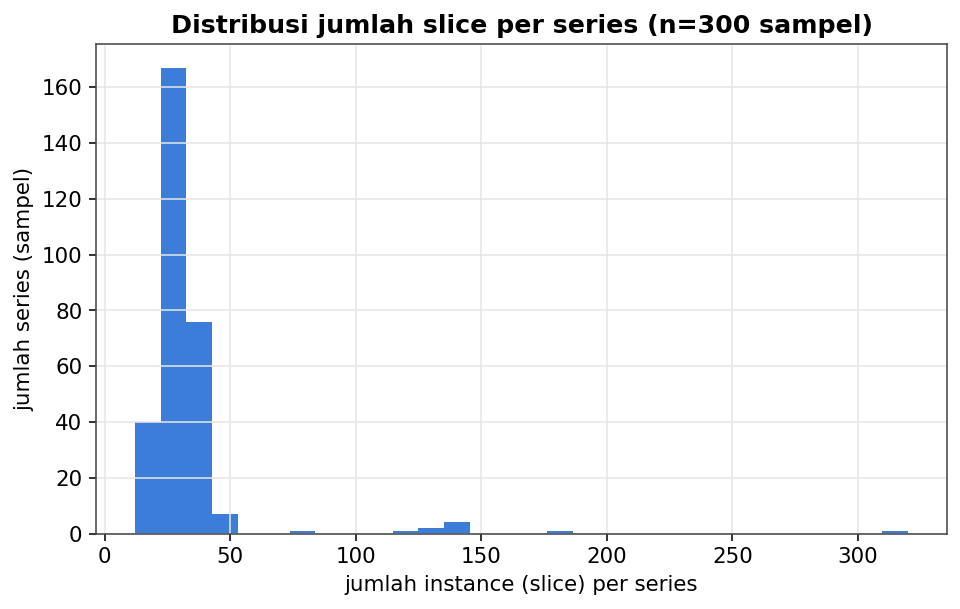

*Disampel dari 300 series acak untuk efisiensi — rata-rata 33.7 slice/series.*

## Distribusi intensitas pixel raw

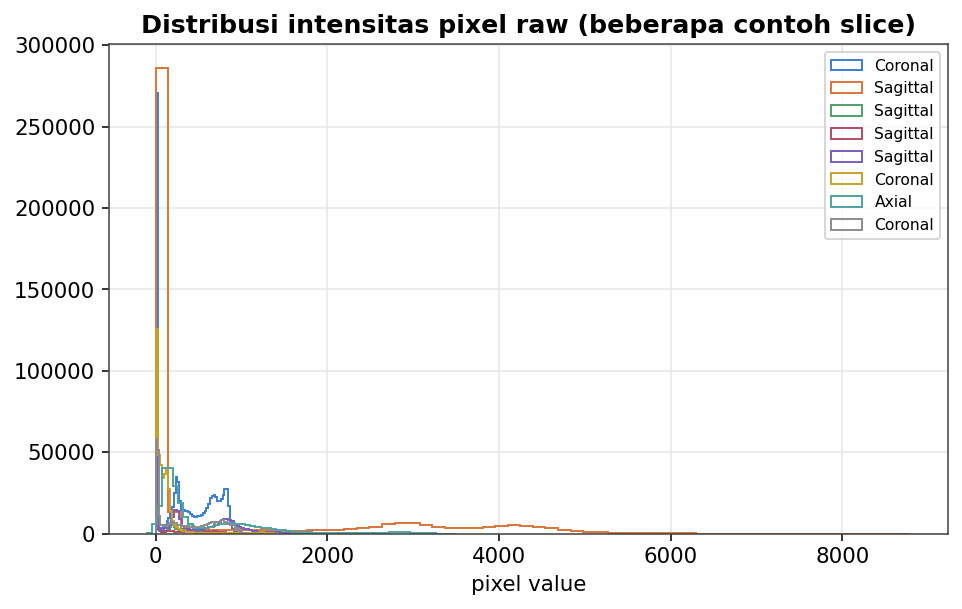

*Histogram nilai pixel mentah dari beberapa contoh slice, per anatomical plane.*

## Heterogenitas scanner (analisis lanjutan)

Membaca header DICOM dari 600 series untuk menilai domain shift antar-scanner.

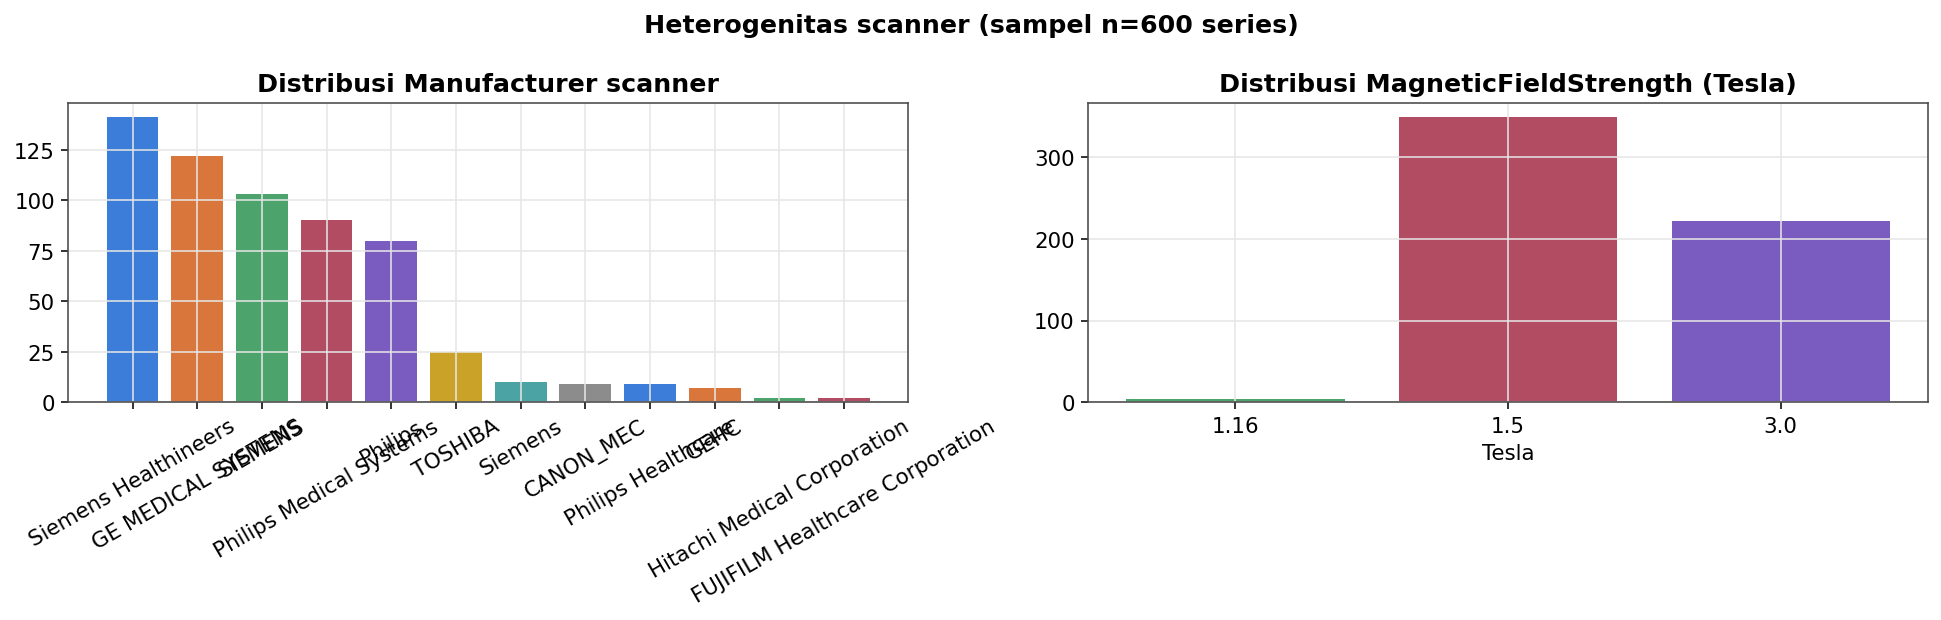

*≥10 vendor scanner berbeda & 3 kekuatan medan magnet (1.16T/1.5T/3.0T) — data jelas multi-institusi/multi-negara.*

## Variasi resolusi & skala fisik

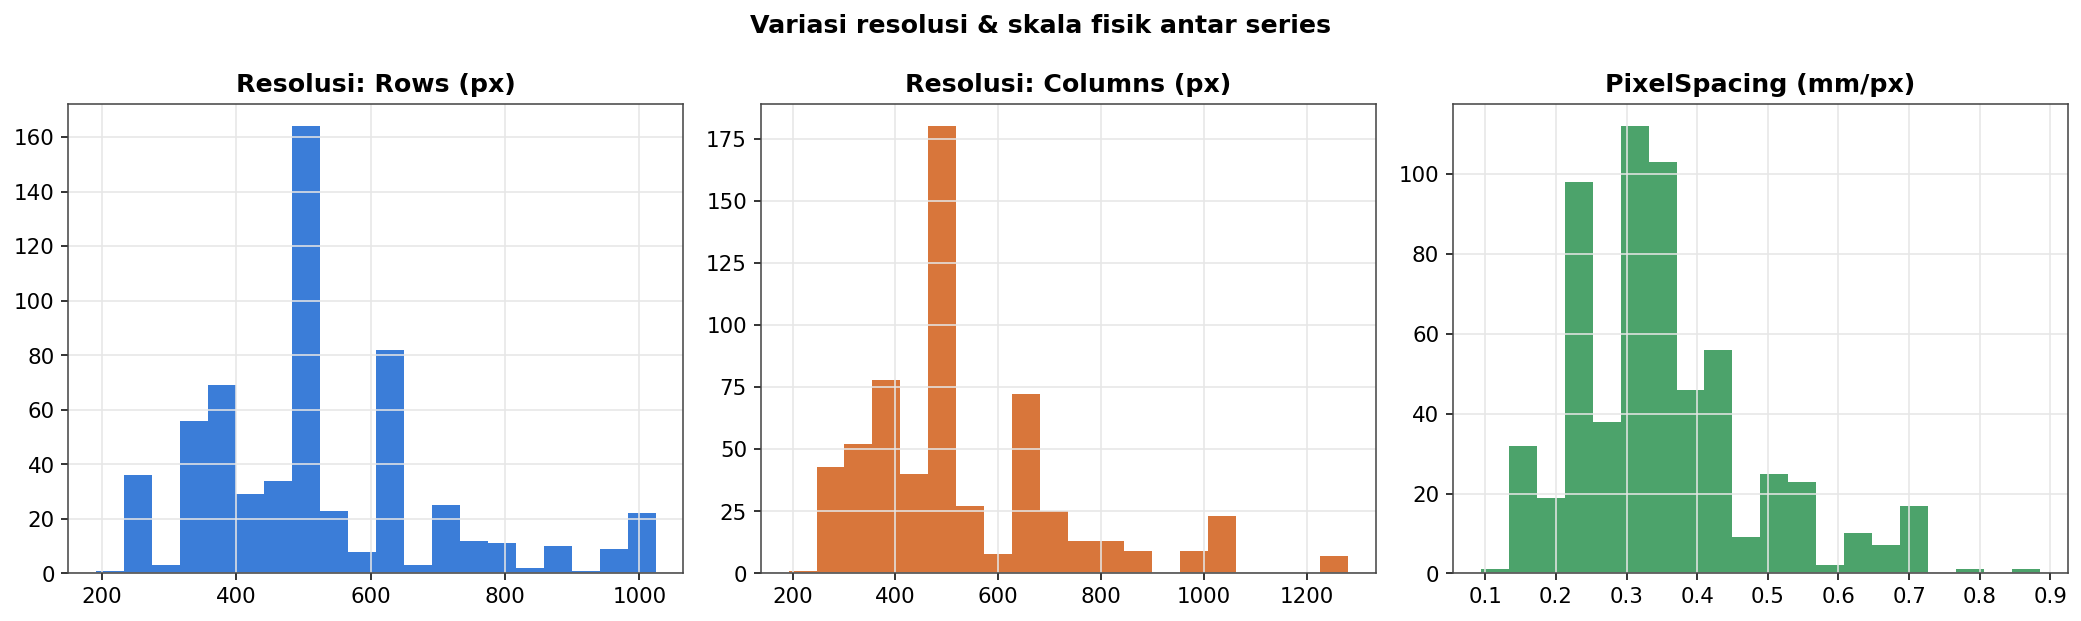

*50 kombinasi (Rows, Columns) unik dari 600 series sampel — resize wajib berbasis PixelSpacing (skala fisik), bukan resize piksel naif.*

## Intensitas per tipe sekuens

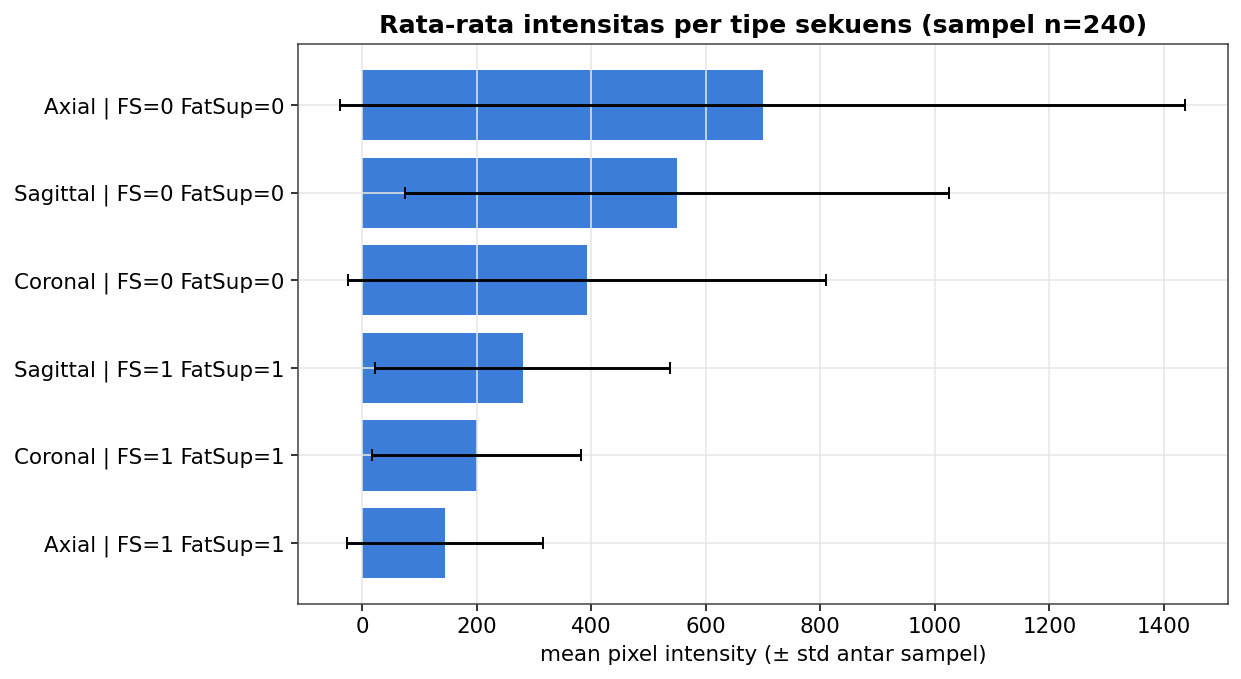

*Mean intensitas berbeda ~5× antara sekuens non-fat-suppressed (~700) vs fat-suppressed fluid-sensitive (~150) — normalisasi harus per-grup sekuens, bukan global.*

## Sapuan slice dalam satu series

Menampilkan 12 dari 23 slice suatu series untuk melihat variasi anatomi dari ujung ke ujung volume.

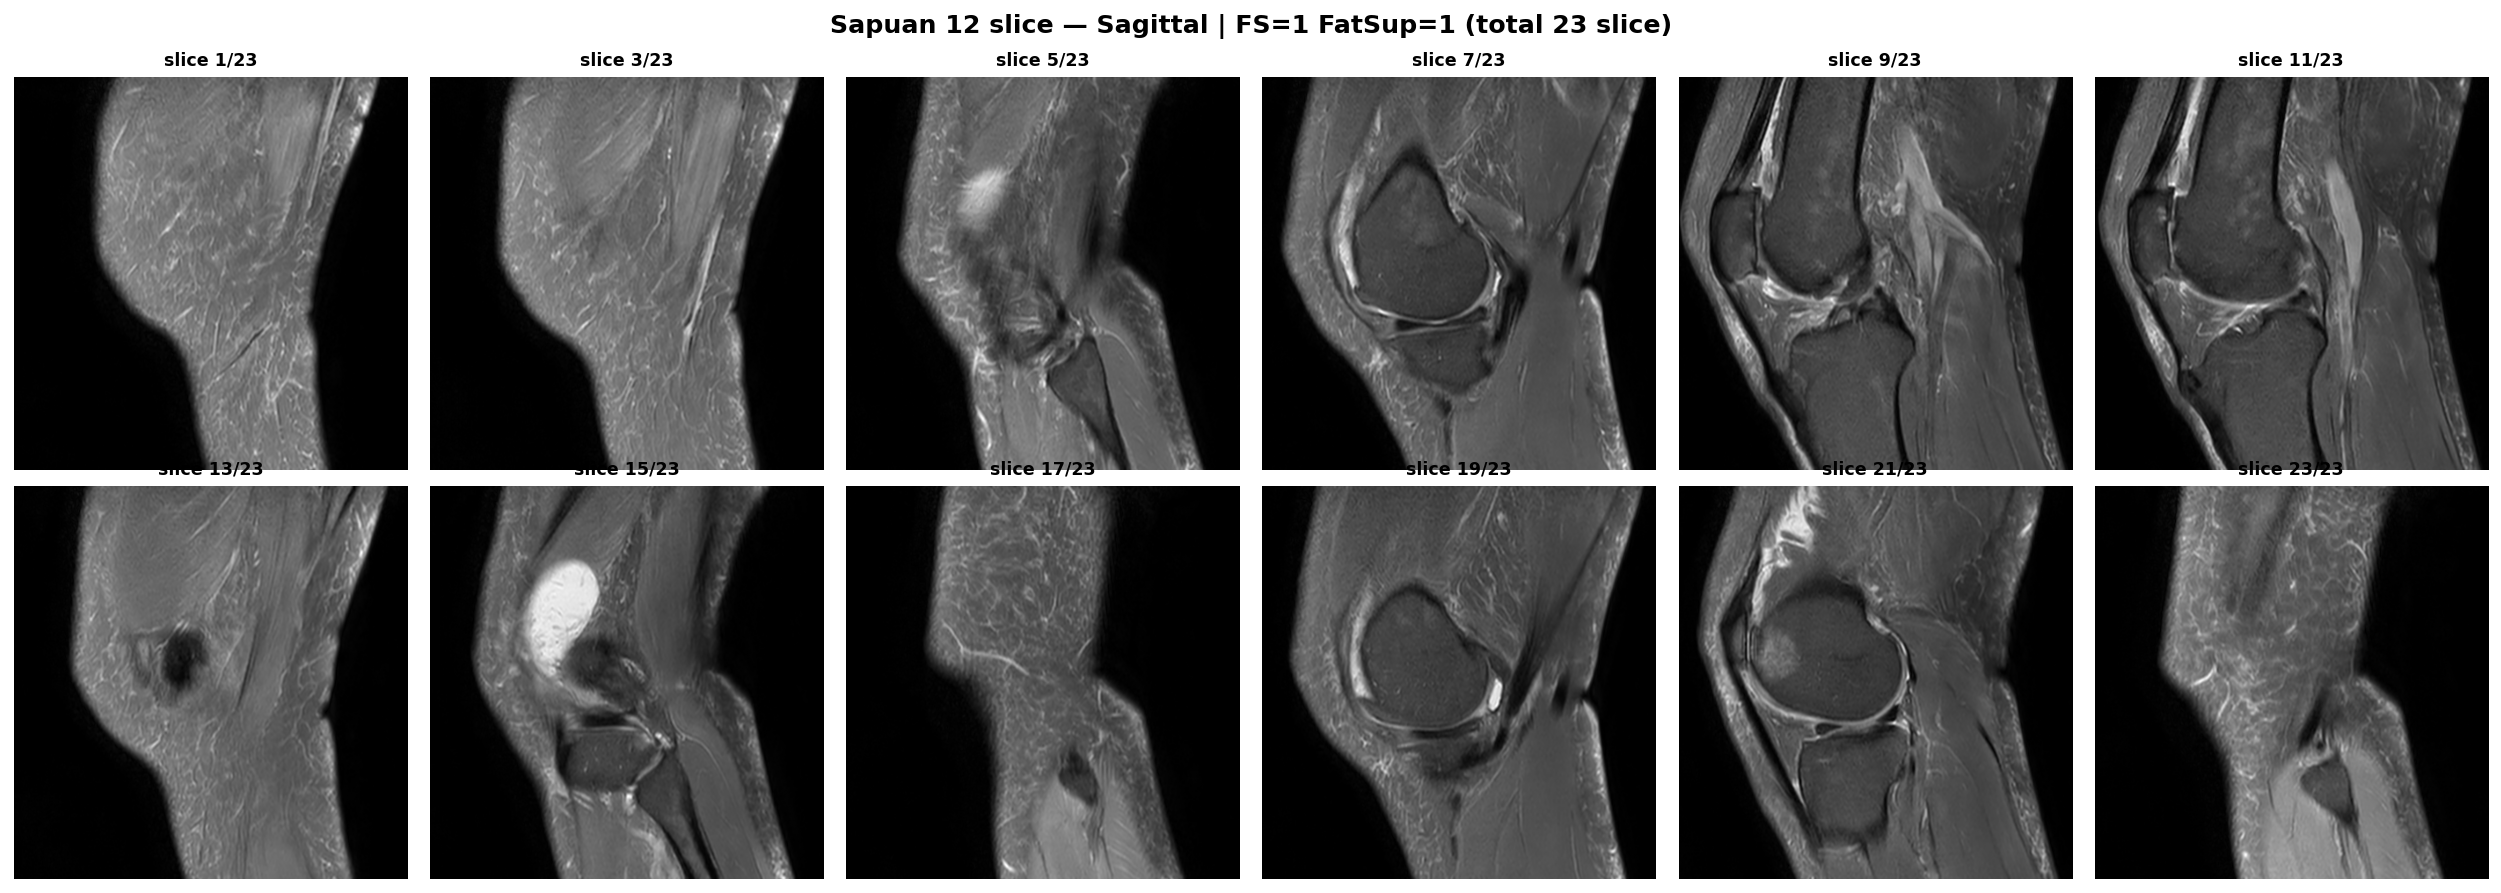

*Struktur terang (kemungkinan kista) di slice 15 tidak muncul di slice lain — bukti nyata perlunya model multi-slice, bukan hanya mid-slice tunggal.*

## Kesimpulan & implikasi modeling

1. **Label sangat jarang (~98.7% missing, hanya 58/4407 studi berlabel penuh).** Sinyal utama ada di teks `Report`, yang tersedia untuk 100% studi (tapi hanya ada di train, tidak di test). Strategi: weak-labeling dari laporan untuk memperluas data latih, lalu semi-supervised training model citra di atasnya.
2. **Laporan sangat multi-bahasa** (≥9 bahasa terdeteksi) — perlu model NLP multilingual atau pipeline terjemahan untuk labeler berbasis teks.
3. **Struktur hierarkis Study → Series (rata-rata 5.5) → Instance (rata-rata 33.7 slice)**, dengan resolusi (50 kombinasi unik), scanner (≥10 vendor), dan intensitas (beda ~5× antar sekuens) yang sangat heterogen. Arsitektur idealnya: 2D backbone per-slice + attention pooling multi-slice & multi-series, dengan normalisasi per-grup-sekuens dan resize berbasis PixelSpacing.
4. **Kualitas data secara teknis bagus** — 0% gagal baca dari 400 series yang diuji (header maupun pixel array).
5. **Test publik hanya 3 studi** — pola *code competition*; jangan overfit ke asumsi statistik dari situ.

**Rekomendasi arsitektur lengkap & roadmap peningkatan bertahap:** lihat artifact terpisah *"Cetak Biru Model Lutut"* yang disusun dari analisis ini.

*Sumber lengkap: log eksekusi ada di `rsna-knee-abnormality-detection-eda.log`, notebook sumber (belum dieksekusi) ada di `../kaggle_kernel/rsna_knee_eda.ipynb`, dan versi live selalu bisa dilihat di [halaman kernel Kaggle](https://www.kaggle.com/code/dimaspashaakrilian/rsna-knee-abnormality-detection-eda).*